# Разведочный анализ данных

Изучение данных, проверка их качества, поиск признаков, по которым бот отличается от человека. Модель здесь не обучается.

## 1. Данные

Библиотеки и оформление графиков.

In [1]:
from pathlib import Path

import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"

HUMAN, BOT, INK = "#2a78d6", "#eb6834", "#333333"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110,
    "axes.edgecolor": "#bbbbbb", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

Три файла с данными. Колонки со временем переводятся в `datetime`.

In [2]:
DATE_COLUMNS = ["cookie_created_at", "window_start_ts", "window_end_ts"]

train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=DATE_COLUMNS)
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=DATE_COLUMNS)
events = pd.read_csv(DATA_DIR / "events.csv.gz", parse_dates=["event_ts"])

print("train:", train.shape, "| test:", test.shape, "| events:", events.shape)

train: (11091, 5) | test: (4909, 4) | events: (328905, 14)


## 2. Куки в train и test

Проверка train и test:

In [3]:
print("уникальных cookie_id: train", train["cookie_id"].nunique(), "из", len(train), "| test", test["cookie_id"].nunique(), "из", len(test))
print("длина окна, часов:", ((train["window_end_ts"] - train["window_start_ts"]).dt.total_seconds() / 3600).unique())
print("train:", train["window_start_ts"].min().date(), "-", train["window_start_ts"].max().date())
print("test: ", test["window_start_ts"].min().date(), "-", test["window_start_ts"].max().date())

уникальных cookie_id: train 11091 из 11091 | test 4909 из 4909
длина окна, часов: [24.]
train: 2026-04-06 - 2026-04-19
test:  2026-04-20 - 2026-04-26


Одна строка на куку, окно везде сутки. Test идёт строго после train, поэтому проверка модели должна идти по времени, а не случайным разбиением.

Доля ботов в train и её изменение по дням.

ботов: 899 из 11091 | доля: 0.081


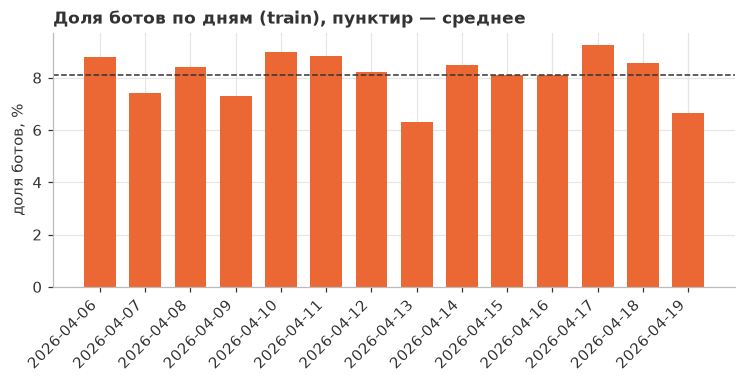

In [4]:
print("ботов:", train["target"].sum(), "из", len(train), "| доля:", round(train["target"].mean(), 3))

by_day = train.groupby(train["window_start_ts"].dt.date)["target"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(by_day.index.astype(str), by_day.values, color=BOT, width=0.7)
ax.axhline(train["target"].mean() * 100, color=INK, lw=1, ls="--")
ax.set_ylabel("доля ботов, %")
ax.set_title("Доля ботов по дням (train), пунктир — среднее")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

Ботов 8,1%. По дням доля держится в пределах 6–9%

## 3. Журнал событий

Журнал событий: число событий на куку и типы событий.

In [5]:
print(events.groupby("cookie_id").size().describe().round(1))
display(events["event_name"].value_counts().to_frame("events").T)

count    16000.0
mean        20.6
std         19.7
min          1.0
25%          8.0
50%         14.0
75%         27.0
max        191.0
dtype: float64


event_name,item_view,search_results_view,photo_swipe,favorite_add,seller_page_view,contact_phone_show,captcha_shown,login,contact_chat_open,contact_message_sent
events,120817,100402,36517,19049,17403,11316,7928,6267,6125,3081


Событий на куку от 1 до 191, медиана 14

Доля пропусков (`missing_share`) по колонкам.

In [6]:
missing = events.isna().mean().round(3)
display(missing[missing > 0].rename("missing_share").to_frame().T)

,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y
missing_share,0.348,0.1,0.072,0.407,0.695,0.695,0.67,0.67


Больше всего пропусков у `search_query` / `search_page` (70%) и `pointer_x/y` (67%). Причины выясняются в разделах про поиск и курсор.

## 4. Чистка журнала

In [7]:
print("полных дубликатов:", events.duplicated().sum())
events = events.drop_duplicates()
print("строк осталось:", len(events))

полных дубликатов: 4863


строк осталось: 324042


Как записана платформа?

In [8]:
display(events["platform"].value_counts().to_frame("events").T)

platform,desktop,WEB,Web,web,ANDROID,Android,android,iOS,iphone,IOS,ios
events,46157,45799,45703,45284,41809,41637,41542,4035,4035,4028,4013


Платформа записана 11 способами, хотя их можно разделить на три значения

Платформа приводится к трём значениям: web, android, ios.

In [9]:
PLATFORM_MAP = {
    "web": "web", "WEB": "web", "Web": "web", "desktop": "web",
    "android": "android", "Android": "android", "ANDROID": "android",
    "ios": "ios", "iOS": "ios", "IOS": "ios", "iphone": "ios",
}
events["platform"] = events["platform"].map(PLATFORM_MAP)
assert events["platform"].notna().all()
print(events["platform"].value_counts().to_dict())

{'web': 182943, 'android': 124988, 'ios': 16111}


In [10]:
print("отсортирован по времени:", events["event_ts"].is_monotonic_increasing)
events = events.sort_values(["cookie_id", "event_ts"]).reset_index(drop=True)

отсортирован по времени: False


Журнал не отсортирован по времени. Сортировка по куке и времени нужна для расчёта пауз между событиями.

Проверка колонки `eid`: дублирует ли она `event_name`.

In [11]:
display(pd.crosstab(events["eid"], events["event_name"]))

event_name,captcha_shown,contact_chat_open,contact_message_sent,contact_phone_show,favorite_add,item_view,login,photo_swipe,search_results_view,seller_page_view
eid,,,,,,,,,,
100,0,0,0,0,0,0,0,0,98929,0
200,0,0,0,0,0,118990,0,0,0,0
210,0,0,0,0,0,0,0,35962,0,0
220,0,0,0,0,0,0,0,0,0,17180
300,0,0,0,11154,0,0,0,0,0,0
301,0,6047,0,0,0,0,0,0,0,0
303,0,0,3032,0,0,0,0,0,0,0
400,0,0,0,0,18739,0,0,0,0,0
500,0,0,0,0,0,0,6178,0,0,0


`eid` просто дублирует `event_name`, не нужен

## 5. События вне окна

Определяю как события относительно окна расположены есть ли до или после, смотрю и по train и по test

In [12]:
meta = pd.concat([train.assign(split="train"), test.assign(split="test")])
events = events.merge(
    meta[["cookie_id", "window_start_ts", "window_end_ts", "split", "target"]], on="cookie_id", how="left"
)
events["position"] = np.select(
    [events["event_ts"] < events["window_start_ts"], events["event_ts"] >= events["window_end_ts"]],
    ["before", "after"],
    default="in_window",
)
display(events.groupby("split")["position"].value_counts(normalize=True).unstack().round(3))

position,after,in_window
split,,
test,NaN,1.000
train,0.171,0.829


В train 17% событий лежат после конца окна, в test таких нет 

Доля событий после окна у людей и ботов (train).

In [13]:
train_events = events[events["split"] == "train"]
display(train_events.groupby("target")["position"].value_counts(normalize=True).unstack().round(3))

position,after,in_window
target,,
0.0,0.110,0.890
1.0,0.425,0.575


После окна лежит 42,5% событий у ботов и 11% у людей. Если оставить эти события, модель научится ловить это, а в test такого нет - получится утечка

Положение каждого типа события относительно окна, особенно `captcha_shown`.

In [14]:
display(pd.crosstab(events["event_name"], events["position"]))

position,after,in_window
event_name,,
captcha_shown,7831,0
contact_chat_open,568,5479
contact_message_sent,254,2778
contact_phone_show,1009,10145
favorite_add,1727,17012
item_view,12542,106448
login,599,5579
photo_swipe,3392,32570
search_results_view,10450,88479


`captcha_shown` лежит только после окна: 7 831 событие, внутри окна ноль. Остальные типы есть и в окне, и после него.

Остаются только события внутри окна. Проверка, что капчи в них нет

In [15]:
events = events[events["position"] == "in_window"].drop(columns="position").reset_index(drop=True)
assert "captcha_shown" not in set(events["event_name"])
print("событий в окне:", len(events))

событий в окне: 283833


## 6. Сколько активности

Число событий на куку в окне: люди и боты.

In [16]:
n_events = events.groupby("cookie_id").size().rename("n_events")
tr = train.merge(n_events, on="cookie_id", how="left")
print("кук без событий в окне:", tr["n_events"].isna().sum())
display(tr.groupby("target")["n_events"].describe().round(1))

кук без событий в окне: 0


,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,10192.0,16.6,15.9,1.0,6.0,12.0,22.0,137.0
1,899.0,29.0,27.1,1.0,11.0,20.0,37.0,165.0


Боты активнее: в среднем 29 событий против 16,6, медиана 20 против 12. Кук без событий в окне нет.

Доля ботов в группах по числу событий.

In [17]:
bucket = pd.cut(tr["n_events"], [0, 3, 6, 12, 25, 50, 1000])
display(tr.groupby(bucket, observed=True)["target"].agg(cookies="size", bot_share="mean").round(3))

,cookies,bot_share
n_events,,
"(0, 3]",1187,0.021
"(3, 6]",1719,0.048
"(6, 12]",2854,0.060
"(12, 25]",2989,0.087
"(25, 50]",1726,0.123
"(50, 1000]",616,0.239


Чем больше событий, тем выше доля ботов: до 3 событий ботов 2%, больше 50 — 24%.

## 7. Время суток

In [18]:
train_events = events[events["split"] == "train"].copy()
train_events["hour"] = train_events["event_ts"].dt.hour
by_hour = pd.crosstab(train_events["hour"], train_events["target"], normalize="columns") * 100
print("доля событий ночью, %:", by_hour.loc[0:5].sum().round(1).to_dict())

доля событий ночью, %: {0.0: 13.0, 1.0: 24.3}


Ночью (00–06) у ботов 24,3% событий, у людей 13,0%.

Активность по часам суток.

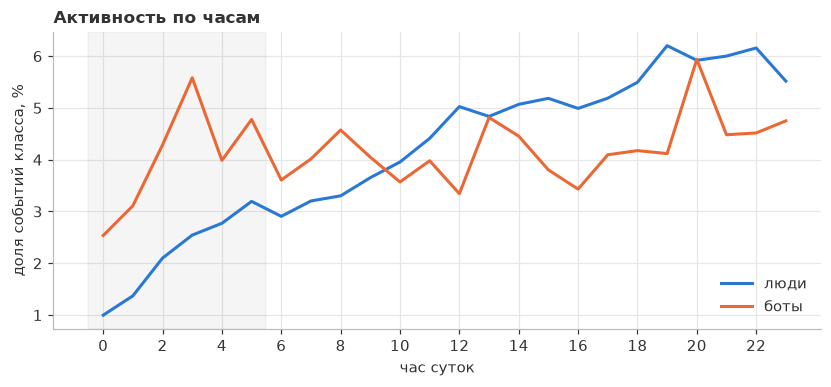

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(by_hour.index, by_hour[0.0], color=HUMAN, lw=2, label="люди")
ax.plot(by_hour.index, by_hour[1.0], color=BOT, lw=2, label="боты")
ax.axvspan(-0.5, 5.5, color="#888888", alpha=0.08)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("час суток")
ax.set_ylabel("доля событий класса, %")
ax.set_title("Активность по часам")
ax.legend()
plt.show()

У людей активность зависит от времени суток, ночью минимальна, вечером самая высокоая, у ботов же активность почти ровная в течение суток

Ночная активность: у всех ботов или у части. Доля ночных событий у каждой куки.

In [20]:
train_events["night"] = train_events["hour"] < 6
night_share = train_events.groupby("cookie_id")["night"].mean().rename("night_share")
tr = tr.merge(night_share, on="cookie_id", how="left")
tr["mostly_night"] = tr["night_share"] > 0.5

print("кук совсем без ночных событий, %:", (tr.groupby("target")["night_share"].apply(lambda s: (s == 0).mean()) * 100).round(1).to_dict())
print("кук с >50% ночных событий, %:", (tr.groupby("target")["mostly_night"].mean() * 100).round(1).to_dict())
print("доля ботов среди кук с >50% ночью:", round(tr.loc[tr["mostly_night"], "target"].mean(), 3),
      "| среди остальных:", round(tr.loc[~tr["mostly_night"], "target"].mean(), 3))

кук совсем без ночных событий, %: {0: 80.7, 1: 69.5}
кук с >50% ночных событий, %: {0: 13.0, 1: 21.5}
доля ботов среди кук с >50% ночью: 0.127 | среди остальных: 0.074


Ночью бывают не все боты: 70% ботов вообще не активны ночью (у людей 81%). Среди кук с большей частью событий ночью ботов 12,7%, среди остальных 7,4%. Признак полезный, но слабый.

## 8. Темп действий

Пауза между соседними событиями куки. Медиана паузы у людей и ботов.

In [21]:
events["gap_s"] = events.groupby("cookie_id")["event_ts"].diff().dt.total_seconds()
median_gap = events.groupby("cookie_id")["gap_s"].median().rename("median_gap_s")
tr = tr.merge(median_gap, on="cookie_id", how="left")
display(tr.groupby("target")["median_gap_s"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,9943.0,226.3,781.2,0.0,38.0,60.5,102.0,9005.0
1,894.0,101.2,253.8,3.0,14.0,25.0,53.8,3777.5


Боты кликают быстрее: типичная пауза между событиями 25 с против 60 с у людей. У кук с одним событием пауз нет (249 людей и 5 ботов).

Доля совсем быстрых пауз (короче секунды).

In [22]:
fast = events[events["split"] == "train"].groupby("target")["gap_s"].apply(lambda s: (s.dropna() < 1).mean() * 100)
print("доля пауз короче секунды, %:", fast.round(2).to_dict())

доля пауз короче секунды, %: {0.0: 0.62, 1.0: 0.14}


Пауз короче секунды почти нет ни у людей, ни у ботов

Ровность пауз: разброс относительно среднего (`gap_cv`) и самая длинная пауза

In [23]:
g = events.groupby("cookie_id")["gap_s"]
reg = pd.DataFrame({"gap_cv": g.std() / g.mean(), "gap_max_s": g.max()})
reg["gap_cv"] = reg["gap_cv"].replace(np.inf, np.nan)
tr = tr.merge(reg, on="cookie_id", how="left")
display(tr.groupby("target")[["gap_cv", "gap_max_s"]].describe().T.round(2))

target                 0        1
gap_cv    count  9557.00   885.00
          mean      2.02     2.65
          std       0.90     1.59
          min       0.00     0.00
          25%       1.38     1.49
          50%       2.04     2.60
          75%       2.60     3.63
          max       6.73     8.29
gap_max_s count  9943.00   894.00
          mean   4966.74  5072.63
          std    3222.53  3126.24
          min       0.00     8.00
          25%    1593.00  2036.75
          50%    5894.00  6053.00
          75%    7886.00  7813.50
          max    9760.00  9608.00

Ожидалось, что у ботов паузы ровнее, но вышло наоборот: разброс пауз у них больше (медиана `gap_cv` 2,6 против 2,0), боты работают рывками. Самая длинная пауза у обоих классов почти одинаковая, признак бесполезен.

Всплески: число событий в самую активную минуту куки.

In [24]:
per_min = events.groupby(["cookie_id", events["event_ts"].dt.floor("min")]).size()
tr = tr.merge(per_min.groupby("cookie_id").max().rename("peak_per_min"), on="cookie_id", how="left")
display(tr.groupby("target")["peak_per_min"].describe().round(1))
peak_bucket = pd.cut(tr["peak_per_min"], [0, 1, 2, 3, 5, 100])
display(tr.groupby(peak_bucket, observed=True)["target"].agg(cookies="size", bot_share="mean").round(3))

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,10192.0,2.5,1.1,1.0,2.0,2.0,3.0,10.0
1,899.0,4.2,3.0,1.0,2.0,4.0,5.0,24.0


,cookies,bot_share
peak_per_min,,
"(0, 1]",1897,0.073
"(1, 2]",4358,0.030
"(2, 3]",2860,0.063
"(3, 5]",1628,0.151
"(5, 100]",348,0.589


Всплески хорошо различают классы: в самую активную минуту у ботов медиана 4 события, у людей 2. Если в какую-то минуту пять и больше событий, среди таких кук 59% ботов (348 кук).

Подробнее про паузы:
- квантили пауз внутри куки (10, 25, 75 и 90%)
- доли пауз короче 5, 15, 30 и 60 секунд

In [25]:
gap = events.groupby("cookie_id")["gap_s"]
gq = pd.DataFrame({f"gap_p{int(p * 100)}": gap.quantile(p) for p in (0.1, 0.25, 0.75, 0.9)})
for t in (5, 15, 30, 60):
    gq[f"gap_lt{t}"] = (events["gap_s"] < t).astype(float).where(events["gap_s"].notna()).groupby(events["cookie_id"]).mean()
tr = tr.merge(gq, on="cookie_id", how="left")
display(tr.groupby("target")[list(gq.columns)].median().round(2).rename(index={0: "люди", 1: "боты"}).T)

target,люди,боты
gap_p10,17.00,9.20
gap_p25,30.50,15.00
gap_p75,128.00,42.38
gap_p90,1619.00,129.70
gap_lt5,0.00,0.00
gap_lt15,0.12,0.26
gap_lt30,0.28,0.58
gap_lt60,0.50,0.84


У ботов паузы короче, при этом пауз короче 5 секунд почти нет ни у кого.

Попробуем посчитать сессии: новая сессия начинается после паузы дольше 30 минут. Результат - число сессий и длительность активности куки в минутах - сколько минут прошло между самым первым и самым последним событием куки в окне 

In [26]:
n_sessions = (1 + (events["gap_s"] > 1800).groupby(events["cookie_id"]).sum()).rename("n_sessions")
bounds = events.groupby("cookie_id")["event_ts"].agg(["min", "max"])
span_min = ((bounds["max"] - bounds["min"]).dt.total_seconds() / 60).rename("span_min")
tr = tr.merge(n_sessions, on="cookie_id", how="left").merge(span_min, on="cookie_id", how="left")
display(tr.groupby("target")[["n_sessions", "span_min"]].describe().round(1).T)

target                  0       1
n_sessions count  10192.0   899.0
           mean       3.0     3.0
           std        2.1     2.0
           min        1.0     1.0
           25%        1.0     2.0
           50%        2.0     2.0
           75%        4.0     4.0
           max       17.0    16.0
span_min   count  10192.0   899.0
           mean     193.7   201.4
           std      205.6   190.6
           min        0.0     0.0
           25%       26.1    54.9
           50%      138.8   151.5
           75%      278.8   280.1
           max     1391.5  1199.3

Число сессий и длительность активности у людей и ботов почти одинаковы. Признак ничего не даёт.

## 9. Что делают в окне

Доля каждого типа событий внутри класса.

In [27]:
train_events = events[events["split"] == "train"]
mix = pd.crosstab(train_events["event_name"], train_events["target"], normalize="columns") * 100
display(mix.round(1).rename(columns={0.0: "люди, %", 1.0: "боты, %"}).sort_values("боты, %"))

target,"люди, %","боты, %"
event_name,,
contact_message_sent,1.0,0.8
login,2.2,0.8
contact_chat_open,2.0,1.4
contact_phone_show,3.7,2.6
favorite_add,6.6,2.7
seller_page_view,5.3,5.9
photo_swipe,12.3,7.0
search_results_view,30.5,35.2
item_view,36.5,43.7


Боты чаще смотрят объявления  и поиск, реже добавляют в избранное , листают фото и логинятся 

## 10. Поиск

Максимальная страница выдачи у каждой куки: люди и боты.

In [28]:
max_page = (
    events[events["event_name"] == "search_results_view"].groupby("cookie_id")["search_page"].max().rename("max_page")
)
tr = tr.merge(max_page, on="cookie_id", how="left")
print("кук без поиска:", tr["max_page"].isna().sum(), "| ботов среди них:", round(tr.loc[tr["max_page"].isna(), "target"].mean(), 3))
display(tr.groupby("target")["max_page"].describe().round(1))

кук без поиска: 921 | ботов среди них: 0.04


,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,9308.0,4.4,3.2,1.0,2.0,4.0,6.0,33.0
1,862.0,9.3,8.1,1.0,3.0,7.0,12.0,63.0


Боты листают выдачу глубже: медиана 7 страниц против 4, максимум 63. Кук без поиска 921, среди них 4% ботов.

Доля ботов по глубине выдачи.

{'1': 3.3, '2': 4.4, '3': 6.3, '4–5': 5.8, '6–10': 10.1, '>10': 35.2}


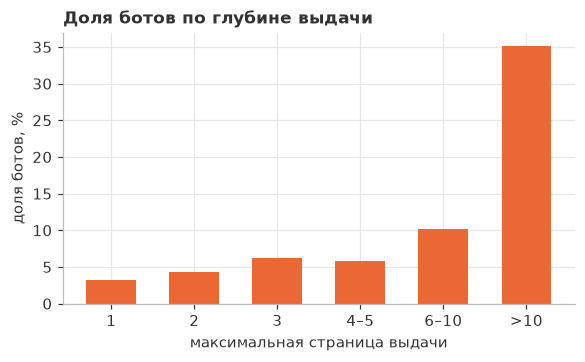

In [29]:
labels = ["1", "2", "3", "4–5", "6–10", ">10"]
page_bucket = pd.cut(tr["max_page"], [0, 1, 2, 3, 5, 10, 100], labels=labels)
bot_share = tr.groupby(page_bucket, observed=True)["target"].mean() * 100
print(bot_share.round(1).to_dict())

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(bot_share.index.astype(str), bot_share.values, color=BOT, width=0.6)
ax.set_xlabel("максимальная страница выдачи")
ax.set_ylabel("доля ботов, %")
ax.set_title("Доля ботов по глубине выдачи")
plt.show()

Доля ботов растёт с глубиной выдачи: на 1–2 страницах 3–4%, глубже 10-й страницы 35%. Один из самых сильных признаков поиска.

Число поисков и число разных запросов у каждой куки.

In [30]:
searches = events[events["event_name"] == "search_results_view"].groupby("cookie_id").agg(
    n_search=("event_ts", "size"), n_queries=("search_query", "nunique")
)
tr = tr.merge(searches, on="cookie_id", how="left")
tr[["n_search", "n_queries"]] = tr[["n_search", "n_queries"]].fillna(0)
tr["queries_per_search"] = tr["n_queries"] / tr["n_search"].where(tr["n_search"] > 0)
display(tr.groupby("target")[["n_search", "n_queries", "queries_per_search"]].describe().T.round(2))

target                           0       1
n_search           count  10192.00  899.00
                   mean       5.07   10.21
                   std        5.12   10.85
                   min        0.00    0.00
                   25%        2.00    3.00
                   50%        4.00    7.00
                   75%        7.00   13.00
                   max       44.00   64.00
n_queries          count  10192.00  899.00
                   mean       3.79    4.76
                   std        3.20    3.14
                   min        0.00    0.00
                   25%        1.00    2.00
                   50%        3.00    4.00
                   75%        5.00    7.00
                   max       29.00   17.00
queries_per_search count   9308.00  862.00
                   mean       0.85    0.66
                   std        0.19    0.26
                   min        0.13    0.12
                   25%        0.71    0.44
                   50%        1.00    0.67
                   75%        1.00    1.00
                   max        1.00    1.00

Поисков у ботов больше (медиана 7 против 4). Запросы у ботов чаще повторяются: на один поиск приходится 0,67 разных запроса (медиана) против 1,0 у людей.

## 11. Разнообразие просмотров

Просмотры объявлений: число разных объявлений, категорий и городов на куку.

In [31]:
views = events[events["event_name"] == "item_view"]
div = views.groupby("cookie_id").agg(
    n_views=("event_ts", "size"), n_items=("item_id", "nunique"),
    n_categories=("item_category", "nunique"), n_locations=("item_location", "nunique"),
)
div["repeat_views"] = 1 - div["n_items"] / div["n_views"]
tr = tr.merge(div, on="cookie_id", how="left")
display(tr.groupby("target")[["n_views", "n_items", "n_categories", "n_locations", "repeat_views"]].describe().T.round(2))

target                    0       1
n_views      count  9479.00  883.00
             mean      6.52   12.91
             std       6.03   13.21
             min       1.00    1.00
             25%       2.00    4.00
             50%       5.00    8.00
             75%       9.00   16.00
             max      54.00   88.00
n_items      count  9479.00  883.00
             mean      5.70   10.16
             std       5.30    9.07
             min       1.00    1.00
             25%       2.00    4.00
             50%       4.00    7.00
             75%       7.00   13.00
             max      43.00   61.00
n_categories count  9479.00  883.00
             mean      1.91    1.61
             std       1.09    0.73
             min       0.00    0.00
             25%       1.00    1.00
             50%       2.00    1.00
             75%       2.00    2.00
             max       8.00    6.00
n_locations  count  9479.00  883.00
             mean      3.51    6.25
             std       2.81    4.72
             min       0.00    1.00
             25%       1.00    3.00
             50%       3.00    5.00
             75%       5.00    9.00
             max      23.00   27.00
repeat_views count  9479.00  883.00
             mean      0.10    0.14
             std       0.14    0.14
             min       0.00    0.00
             25%       0.00    0.00
             50%       0.00    0.12
             75%       0.19    0.24
             max       0.75    0.62

Разных объявлений у ботов больше (в среднем 10 против 6), но это во многом от общей активности.

То же для кук с 10 и более просмотрами, чтобы отделить разнообразие от общей активности. Доля самой частой категории.

In [32]:
top_cat = views.groupby(["cookie_id", "item_category"]).size()
top_cat_share = (top_cat.groupby("cookie_id").max() / top_cat.groupby("cookie_id").sum()).rename("top_cat_share")
tr = tr.merge(top_cat_share, on="cookie_id", how="left")

heavy = tr[tr["n_views"] >= 10]
print("кук с >=10 просмотров:", heavy.groupby("target").size().to_dict())
display(heavy.groupby("target")[["n_items", "n_categories", "n_locations", "top_cat_share"]].median().round(2))

кук с >=10 просмотров: {0: 1982, 1: 395}


,n_items,n_categories,n_locations,top_cat_share
target,,,,
0,12.0,3.0,7.0,0.60
1,14.0,2.0,9.0,0.91


Среди кук с 10 и более просмотрами число разных объявлений у людей и ботов близко (12 и 14). Зато боты сидят почти в одной категории: на самую частую у них приходится 91% просмотров, у людей 60%. Городов у ботов больше (9 против 7).

Смысл значения `item_id` (номера объявления).

In [33]:
display(views.groupby("target")["item_id"].describe().round(0))

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0.0,61790.0,1030023.0,17276.0,1000000.0,1015037.0,1029934.0,1044983.0,1059999.0
1.0,11396.0,1029742.0,17140.0,1000046.0,1014454.0,1030013.0,1044668.0,1059999.0


Номер объявления у людей и ботов одинаковый (среднее около 1,03 млн у обоих), само значение `item_id` ничего не даёт. Полезно только число разных объявлений.

Считаем для каждой куки, насколько популярны объявления, которые она смотрела (сколько других кук смотрели то же самое за N дней до этого), и сравниваем окна 0/3/7 дней и всю историю по стабильности train/test

In [34]:
views_d = events[events["event_name"] == "item_view"][["cookie_id", "item_id", "window_start_ts"]].copy()
views_d["d"] = (views_d["window_start_ts"] - pd.Timestamp("2026-04-06")).dt.days
per_day = views_d.groupby(["item_id", "d"])["cookie_id"].nunique().unstack(fill_value=0).reindex(columns=range(21), fill_value=0)
cum = per_day.cumsum(axis=1).values
rows = per_day.index.get_indexer(views_d["item_id"])
days = views_d["d"].values

def popularity(K):
    lo = np.where(days - K - 1 >= 0, cum[rows, np.maximum(days - K - 1, 0)], 0) if K is not None else 0
    other = cum[rows, days] - lo - 1
    return pd.Series(np.log1p(other)).groupby(views_d["cookie_id"].values).mean()

split_of = meta.set_index("cookie_id")["split"]
target_of = tr.set_index("cookie_id")["target"]
platform_of = events.groupby("cookie_id")["platform"].agg(lambda s: s.mode().iat[0])
mob_ids = tr.loc[tr["cookie_id"].map(platform_of).isin(["android", "ios"]), "cookie_id"]
out = {}
for K, name in ((0, "только день окна"), (3, "3 дня"), (7, "7 дней"), (None, "вся прошлая история")):
    p = popularity(K)
    is_tr = split_of.reindex(p.index) == "train"
    m = p.reindex(mob_ids).dropna()
    out[name] = {"среднее train": p[is_tr].mean(), "среднее test": p[~is_tr].mean(),
                 "AUC на мобильных": roc_auc_score(target_of.loc[m.index], m)}
display(pd.DataFrame(out).T.round(3))
tr = tr.merge(popularity(3).rename("pop_d3").rename_axis("cookie_id"), on="cookie_id", how="left")

,среднее train,среднее test,AUC на мобильных
только день окна,0.061,0.061,0.625
3 дня,0.206,0.203,0.688
7 дней,0.325,0.377,0.666
вся прошлая история,0.377,0.787,0.656


Вся история даёт нестабильное среднее между train и test (0,38 против 0,79), а окно 3 дня — стабильное (0,206 против 0,203) и при этом неплохо отличает ботов на мобильных (AUC 0,69), поэтому его и берём как признак.

## 12. Курсор мыши

Доля событий с координатами курсора на каждой платформе.

In [35]:
has_ptr = events["pointer_x"].notna().rename("share_with_pointer")
display(has_ptr.groupby(events["platform"]).mean().round(3).to_frame())

,share_with_pointer
platform,
android,0.000
ios,0.000
web,0.593


Курсор есть только у web: на android и ios его нет совсем, у web он заполнен у 59% событий.

Доля событий с курсором у каждой web-куки. Три группы: курсора нет, есть у части событий, есть во всех.

In [36]:
web_events = events[events["platform"] == "web"]
ptr_share = web_events["pointer_x"].notna().groupby(web_events["cookie_id"]).mean().rename("ptr_share")
tr = tr.merge(ptr_share, on="cookie_id", how="left")

web_tr = tr[tr["ptr_share"].notna()]
ptr_group = pd.cut(web_tr["ptr_share"], [-0.01, 0, 0.999, 1], labels=["нет ни в одном", "у части", "во всех"])
display(pd.crosstab(ptr_group, web_tr["target"], normalize="columns").round(3))
display(web_tr.groupby(ptr_group, observed=True)["target"].agg(cookies="size", bot_share="mean").round(3))

target,0,1
ptr_share,,
нет ни в одном,0.288,0.573
у части,0.336,0.255
во всех,0.376,0.172


,cookies,bot_share
ptr_share,,
нет ни в одном,1871,0.180
у части,1939,0.077
во всех,2107,0.048


Без курсора вообще (ни в одном событии) 57% web-ботов и 29% web-людей. Среди web-кук без курсора ботов 18%, у кук с курсором в части событий 7,7%, с курсором во всех событиях 4,8%.

Координаты курсора: различаются ли они у людей и ботов.

In [37]:
ptr_events = events[(events["split"] == "train") & events["pointer_x"].notna()]
display(ptr_events.groupby("target")[["pointer_x", "pointer_y"]].describe().T.round(0))

target               0.0     1.0
pointer_x count  58867.0  6416.0
          mean     957.0   685.0
          std      554.0   363.0
          min        0.0     0.0
          25%      477.0   394.0
          50%      954.0   668.0
          75%     1438.0   952.0
          max     1919.0  1920.0
pointer_y count  58867.0  6416.0
          mean     541.0   507.0
          std      311.0   259.0
          min        0.0     0.0
          25%      274.0   326.0
          50%      542.0   496.0
          75%      809.0   693.0
          max     1080.0  1080.0

Координаты курсора различаются. У людей курсор разбросан по всему экрану (x в среднем 957 при ширине 1920, разброс 554), у ботов сдвинут влево и собран плотнее (x в среднем 685, разброс 363). По y разница небольшая.

Распределение координаты x курсора у людей и ботов (train).

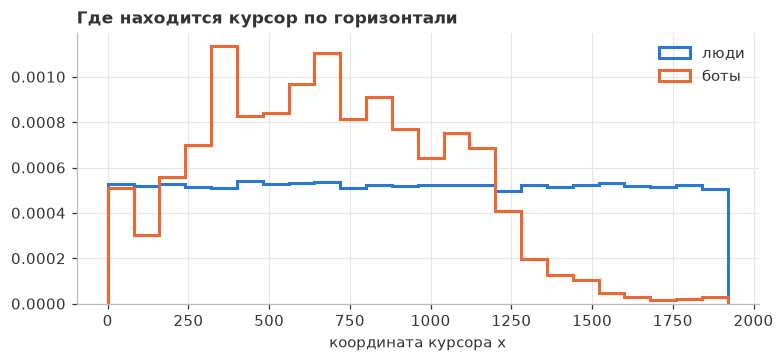

In [38]:
ptr = events[(events["split"] == "train") & events["pointer_x"].notna()]
bins = np.linspace(0, 1920, 25)

fig, ax = plt.subplots(figsize=(8, 3.2))
for value, label, color in ((0.0, "люди", HUMAN), (1.0, "боты", BOT)):
    ax.hist(ptr.loc[ptr["target"] == value, "pointer_x"], bins=bins, density=True, histtype="step", lw=2, color=color, label=label)
ax.set_xlabel("координата курсора x")
ax.set_title("Где находится курсор по горизонтали")
ax.legend()
plt.show()

У людей курсор распределён по всей ширине экрана, у ботов собран в одной области.

Форма распределения курсора у каждой куки: среднее и разброс по x, доля точек у левого края (x < 300), доля разных положений, средняя длина шага между событиями.

In [39]:
g = ptr.groupby("cookie_id")
shape = pd.DataFrame({
    "ptr_x_mean": g["pointer_x"].mean(), "ptr_x_std": g["pointer_x"].std(),
    "left_share": (ptr["pointer_x"] < 300).groupby(ptr["cookie_id"]).mean(),
    "uniq_pos_share": ptr.assign(pos=ptr["pointer_x"].astype(str) + "_" + ptr["pointer_y"].astype(str)).groupby("cookie_id")["pos"].nunique() / g.size(),
    "step_mean": np.hypot(g["pointer_x"].diff(), g["pointer_y"].diff()).groupby(ptr["cookie_id"]).mean(),
})
tr = tr.merge(shape, on="cookie_id", how="left")
display(tr.groupby("target")[list(shape.columns)].median().round(2).rename(index={0: "люди", 1: "боты"}).T)

target,люди,боты
ptr_x_mean,963.65,665.94
ptr_x_std,552.90,202.54
left_share,0.14,0.05
uniq_pos_share,1.00,1.00
step_mean,791.40,368.76


На уровне куки разница ещё сильнее: разброс по x у человека около 550, у бота около 200. Шаг курсора между событиями у ботов короче (370 против 790). Доля разных положений не нужна: почти все положения у всех разные (1,0).

## 13. Платформа и user-agent

Платформа куки (самая частая среди её событий). Доля ботов по платформам.

In [40]:
cookie_platform = events.groupby("cookie_id")["platform"].agg(lambda s: s.mode().iat[0]).rename("platform")
tr = tr.merge(cookie_platform, on="cookie_id", how="left")
display(tr.groupby("platform")["target"].agg(cookies="size", bot_share="mean").round(3))

,cookies,bot_share
platform,,
android,4595,0.062
ios,579,0.045
web,5917,0.099


Платформы отличаются немного: web 9,9% ботов, android 6,2%, ios 4,5%.

User-agent

In [41]:
ua = events["user_agent"].value_counts()
print("разных user_agent:", len(ua))
print("событий приложения Avito:", ua[ua.index.str.startswith("Avito/")].sum())
print("событий с HeadlessChrome:", ua[ua.index.str.contains("Headless")].sum())
display(ua[~ua.index.str.startswith(("Mozilla", "Avito/"))].to_frame("events"))

разных user_agent: 148
событий приложения Avito: 51361
событий с HeadlessChrome: 10280


,events
user_agent,
node-fetch/3.3.2,1036
python-urllib3/2.0.7,1035
Scrapy/2.11.0 (+https://scrapy.org),979
curl/8.1.2,969
Go-http-client/1.1,962
python-requests/2.31.0,865


Три грубые группы user-agent:
- `script`: Headless, Scrapy, curl, Go-http-client, python, node-fetch
- `app`: приложение Avito
- `browser`: остальное

Доля ботов по группам.

In [42]:
SCRIPT_UA = r"Headless|Scrapy|curl|Go-http-client|python|node-fetch"
events["ua_kind"] = np.select(
    [events["user_agent"].str.contains(SCRIPT_UA, case=False), events["user_agent"].str.startswith("Avito/")],
    ["script", "app"],
    default="browser",
)
cookie_ua = events.groupby("cookie_id")["ua_kind"].agg(lambda s: s.mode().iat[0]).rename("ua_kind")
tr = tr.merge(cookie_ua, on="cookie_id", how="left")

display(tr.groupby("ua_kind")["target"].agg(cookies="size", bot_share="mean").round(3))
display(pd.crosstab(tr["platform"], tr["ua_kind"]))

,cookies,bot_share
ua_kind,,
app,2141,0.092
browser,8464,0.069
script,486,0.245


ua_kind,app,browser,script
platform,,,
android,1754,2841,0
ios,387,192,0
web,0,5431,486


Скриптовые user-agent есть только у web-кук (486). Ботов среди них 24,5%, больше, чем в остальных группах (7–9%), но три четверти таких кук всё равно люди. Само по себе script-UA бота не определяет.

Обратная сторона: какая доля всех ботов использует script-UA.

In [43]:
display((pd.crosstab(tr["ua_kind"], tr["target"], normalize="columns") * 100).round(1).rename(columns={0: "люди, %", 1: "боты, %"}))

target,"люди, %","боты, %"
ua_kind,,
app,19.1,21.9
browser,77.3,64.8
script,3.6,13.2


Script-UA есть только у 13% ботов (у людей 3,6%). Остальные 87% ботов выглядят как обычные браузеры или приложение, по user-agent основную массу ботов не поймать.

Число разных user-agent у одной куки.

In [44]:
n_ua = events.groupby("cookie_id")["user_agent"].nunique().rename("n_ua")
tr = tr.merge(n_ua, on="cookie_id", how="left")
display(tr.groupby("n_ua")["target"].agg(cookies="size", bot_share="mean").round(3))

,cookies,bot_share
n_ua,,
1,10295,0.082
2,107,0.009
3,689,0.073


Число разных user-agent у куки на долю ботов не влияет: 8,2% при одном и 7,3% при трёх, кук с двумя всего 107. Не нужен.

In [45]:
chrome = events["user_agent"].str.extract(r"Chrome/(\d+)")[0].astype(float)
chrome_by_cookie = chrome.groupby(events["cookie_id"]).median().rename("chrome_version")
tr = tr.merge(chrome_by_cookie, on="cookie_id", how="left")
display(tr.groupby("target")["chrome_version"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,6768.0,119.4,3.6,112.0,117.0,120.0,122.0,125.0
1,539.0,118.7,3.7,112.0,116.0,118.0,122.0,125.0


Версия Chrome у ботов чуть ниже (медиана 118 против 120), разница небольшая, и версия есть не у всех кук (у 539 из 899 ботов). Слабый признак

## 14. Возраст куки

Возраст куки на начало окна в днях: люди и боты.

In [46]:
tr["age_days"] = (tr["window_start_ts"] - tr["cookie_created_at"]).dt.days
display(tr.groupby("target")["age_days"].describe().round(1))
print("доля кук нулевого возраста, %:", (tr.groupby("target")["age_days"].apply(lambda s: (s == 0).mean()) * 100).round(1).to_dict())

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,10192.0,73.4,67.0,0.0,18.0,61.0,110.0,449.0
1,899.0,48.2,62.8,0.0,0.0,18.0,83.0,361.0


доля кук нулевого возраста, %: {0: 10.4, 1: 25.9}


Боты моложе: медиана возраста куки 18 дней против 61 у людей. Около 26% ботов созданы в день начала окна, у людей таких 10%.

Доля ботов по возрасту куки.

          cookies  bot_share
age_days                    
0            1296      0.180
1–7          1356      0.148
8–30          978      0.050
31–90        3841      0.057
>90          3620      0.054


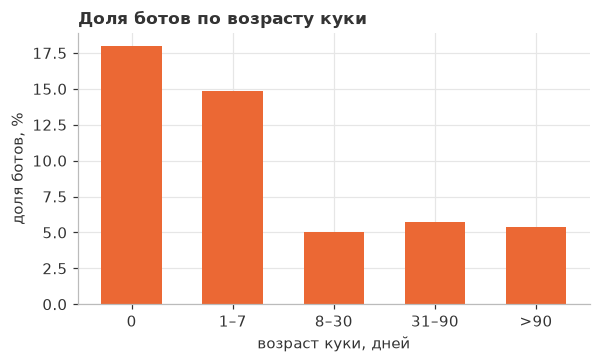

In [47]:
labels = ["0", "1–7", "8–30", "31–90", ">90"]
age_bucket = pd.cut(tr["age_days"], [-1, 0, 7, 30, 90, 10_000], labels=labels)
print(tr.groupby(age_bucket, observed=True)["target"].agg(cookies="size", bot_share="mean").round(3))
bot_share = tr.groupby(age_bucket, observed=True)["target"].mean() * 100

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(bot_share.index.astype(str), bot_share.values, color=BOT, width=0.6)
ax.set_xlabel("возраст куки, дней")
ax.set_ylabel("доля ботов, %")
ax.set_title("Доля ботов по возрасту куки")
plt.show()

У кук младше недели ботов 15–18%, у кук старше недели около 5%. Возраст куки хороший признак, особенно первые дни.

## 15. Мобильные куки

Мобильные user-agent: приложение Avito или мобильный Chrome, версия приложения, устройство. Доля ботов по каждому.

In [48]:
def parse_ua(u):
    m = re.match(r"Avito/(\d+)\.0 \((?:Android (\d+); ([^)]+)|iPhone; iOS ([\d.]+);)", u)
    if m:
        return ("app", float(m.group(1)), float(m.group(2) or m.group(4)), m.group(3) or "iPhone")
    m = re.search(r"Android (\d+); ([^)]+)\).*Chrome/(\d+)", u)
    if m:
        return ("chrome_m", np.nan, float(m.group(1)), m.group(2))
    if "iPhone" in u:
        return ("safari_ios", np.nan, np.nan, "iPhone")
    return ("web", np.nan, np.nan, "desktop")

uas = events["user_agent"].drop_duplicates()
parts = pd.DataFrame([parse_ua(u) for u in uas], index=uas, columns=["ua_form", "app_version", "os_version", "device"])
top = lambda s: s.dropna().mode().iat[0] if s.notna().any() else np.nan
by_cookie = events[["cookie_id", "user_agent"]].join(parts, on="user_agent").groupby("cookie_id").agg(top)
tr = tr.merge(by_cookie, on="cookie_id", how="left")

mob = tr[tr["platform"].isin(["android", "ios"])]
print("мобильных кук:", len(mob), "| ботов:", int(mob["target"].sum()))
for col in ["ua_form", "app_version", "device"]:
    display(mob.groupby(col)["target"].agg(cookies="size", bot_share="mean").round(3).sort_values("bot_share"))

мобильных кук: 5174 | ботов: 311


,cookies,bot_share
ua_form,,
chrome_m,2841,0.037
safari_ios,192,0.047
app,2141,0.092


,cookies,bot_share
app_version,,
118.0,643,0.058
120.0,700,0.090
122.0,798,0.122


,cookies,bot_share
device,,
Pixel 6,706,0.030
Redmi Note 11,687,0.035
SM-G991B,718,0.040
iPhone,579,0.045
SM-A515F,1298,0.067
SM-A125F,592,0.068
M2101K6G,594,0.141


На мобильных доля ботов выше в приложении (9,2%), чем в мобильном Chrome (3,7%), и растёт с версией приложения (118: 5,8%, 120: 9,0%, 122: 12,2%). По устройству выделяется M2101K6G: 14,1% ботов при 3–7% у остальных.

Какие признаки отличают ботов от людей отдельно на мобильных и на web

In [49]:
cand = ["median_gap_s", "peak_per_min", "n_events", "n_items", "n_locations", "n_search", "max_page", "gap_cv", "night_share",
        "top_cat_share", "n_categories", "age_days", "pop_d3", "gap_lt30", "ptr_share", "ptr_x_std"]

def strength(mask):
    res = {}
    for c in cand:
        d = tr.loc[mask, [c, "target"]].dropna()
        if d["target"].nunique() == 2:
            a = roc_auc_score(d["target"], d[c])
            res[c] = max(a, 1 - a)
    return pd.Series(res)

is_mob = tr["platform"].isin(["android", "ios"])
display(pd.DataFrame({"мобильные": strength(is_mob), "web": strength(~is_mob)}).sort_values("мобильные", ascending=False).round(2))

,мобильные,web
median_gap_s,0.75,0.71
gap_lt30,0.73,0.71
peak_per_min,0.70,0.69
pop_d3,0.69,0.69
n_locations,0.64,0.73
age_days,0.62,0.64
n_items,0.62,0.70
n_events,0.62,0.69
top_cat_share,0.57,0.58
gap_cv,0.56,0.65


На мобильных ботов лучше всего отличают тайминг (медианная пауза, доля коротких пауз, пик событий в минуту) и популярность объявлений. Глубина выдачи и число поисков, сильные на web (0,78 и 0,72), на мобильных почти не работают (0,56). Курсора на мобильных нет, а на web один разброс курсора по x различает классы почти полностью (0,94). Поэтому мобильные боты — самое трудное место.

## 16. Корреляция и выбросы

Корреляция признаков

median_gap_s   -0.22
ptr_share      -0.17
age_days       -0.13
night_share     0.08
gap_cv          0.12
n_search        0.16
n_events        0.16
n_items         0.17
pop_d3          0.19
peak_per_min    0.19
max_page        0.20
пары признаков с корреляцией выше 0.7 по модулю:
n_events  n_search    0.89
          n_items     0.91
n_items   n_search    0.74


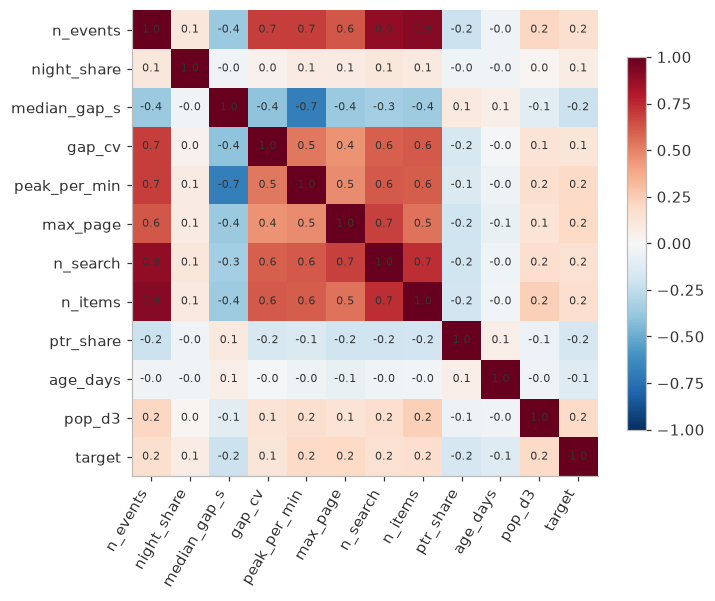

In [50]:
num_cols = ["n_events", "night_share", "median_gap_s", "gap_cv", "peak_per_min", "max_page",
            "n_search", "n_items", "ptr_share", "age_days", "pop_d3"]
corr = tr[num_cols + ["target"]].corr(method="spearman")
print(corr["target"].drop("target").sort_values().round(2).to_string())
pairs = corr.drop(index="target", columns="target").stack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]
print("пары признаков с корреляцией выше 0.7 по модулю:")
print(pairs[pairs.abs() > 0.7].round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Ни один признак не связан с меткой сильнее 0,22: больше всего медианная пауза (−0,22), глубина выдачи (0,20), пик событий в минуту и популярность объявлений (0,19). Одного признака мало, нужна их комбинация. Число событий, число поисков и число разных объявлений сильно связаны между собой (0,74–0,91), это почти одно и то же.

Выбросы по числу событий: верхний 1%.

In [51]:
q99 = tr["n_events"].quantile(0.99)
top = tr[tr["n_events"] > q99]
print("порог верхнего 1%:", q99, "событий | кук:", len(top), "| доля ботов среди них:", round(top["target"].mean(), 3))
print("доля кук класса в верхнем 1%, %:", (tr.groupby("target")["n_events"].apply(lambda s: (s > q99).mean() * 100)).round(1).to_dict())

порог верхнего 1%: 86.0 событий | кук: 108 | доля ботов среди них: 0.417
доля кук класса в верхнем 1%, %: {0: 0.6, 1: 5.0}


В верхнем 1% по числу событий (больше 86) 108 кук, и 42% из них боты. В этот хвост попадают 5% ботов и 0,6% людей: очень активная кука скорее всего бот, но большинство ботов не выбросы.

## Итог

- **Утечка:** в train есть события после конца окна (у ботов их вчетверо больше, чем у людей), в test их нет. Признаки считаются только по событиям внутри окна, `captcha_shown` не используется.
- **Поведение ботов:** больше событий и всплески (пять и больше событий в минуту), короткие паузы, глубокая выдача, почти одна категория, объявления, которые открывают и другие куки, более молодые куки.
- **Курсор:** у web-кук главный признак. Разброс положения курсора по x почти полностью разделяет боты и людей: у ботов курсор собран в одной области, у людей по всему экрану.
- **Мобильные куки:** курсора нет, боты отличаются в основном таймингом и популярностью объявлений, глубина выдачи почти не помогает. Доля ботов выше в приложении и у отдельных версий и устройств. Это самое трудное место.
- **Слабые или лишние:** номер объявления, `eid`, число разных UA, сессии, доля очень коротких пауз. Ночь и user-agent только вспомогательные: 70% ботов не бывают ночью, 87% ботов не выдают себя UA.
- Каждый признак по отдельности слабый (связь с меткой до 0,22), нужна их комбинация.